# What does fairness cost?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-quality-governance/fairness-accuracy-frontier/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-quality-governance/fairness-accuracy-frontier/demo.ipynb)

Everyone agrees fairness has a price. This notebook measures it: the whole trade-off curve between the selection
ratio of two groups and the hit rate of the people selected, scored against two rulers. Ruler 1 is the past
decisions the model learned from, the only one a team usually has. Ruler 2 is true merit, which this constructed
world knows. Group B really is a little less skilled here (0.25 sd), and past decisions also held B to a higher bar.

1. The engine
2. Where each model lands
3. The frontier and the price of parity
4. How much of the price is the ruler
5. The price as a team would estimate it
6. The chart
7. Try your own

## 1. The engine

Extracted from `frontier.py` at build time. `fit_score` trains gradient boosting on the biased history.
`select_at_ratio` selects 30% with group-specific cut-offs so that rate(B) / rate(A) equals a target ratio; within a
group it takes the top scores, which is the best possible selection for that count, so sweeping the ratio draws the
frontier for that score. `study` repeats everything over the same three seeds as `evidence.py` (about 30 seconds),
so the numbers match `evidence.txt` exactly.

In [1]:
from __future__ import annotations

from typing import Dict, List, Optional

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier

SEEDS = [198, 199, 200]


N = 60_000


SELECT = 0.30


RATIOS = [round(0.05 + 0.01 * i, 2) for i in range(121)]  # 0.05 .. 1.25


AUDIT_N = [2_000, 20_000]


AUDIT_REPS = 400


BIAS_SWEEP = [0.0, 0.35, 0.7, 1.05]


READ_AT = [0.25, 0.5, 0.8, 1.0, 1.25]


WORLD: Dict[str, float] = {
    "share_b": 0.30,  # share of applicants in group B
    "skill_gap": 0.25,  # REAL difference in true skill, B lower (sd)
    "label_bias": 0.7,  # extra bar past decisions held B to (sd)
    "label_noise": 0.6,
    "cert_skill": 0.8,  # certification reflects skill
    "exp_skill": 0.6,  # experience reflects skill ...
    "exp_gap": 0.4,  # ... and is depressed for B by access
    "zip_gap": 1.3,  # neighbourhood index, a pure proxy
}


MODELS: Dict[str, Dict[str, object]] = {
    "aware (group as a feature)": {"cols": ["cert", "exp", "zip"], "with_g": True},
    "unaware (group removed)": {"cols": ["cert", "exp", "zip"]},
    "drop zip": {"cols": ["cert", "exp"]},
    "reweighed (Kamiran-Calders)": {"cols": ["cert", "exp", "zip"], "reweigh": True},
}


FRONTIER_MODEL = "aware (group as a feature)"


def generate(n: int = N, seed: int = 198, world: Optional[Dict[str, float]] = None) -> Dict[str, np.ndarray]:
    w = world or WORLD
    rng = np.random.default_rng(seed)
    g = (rng.random(n) < w["share_b"]).astype(int)
    skill = rng.normal(0, 1, n) - w["skill_gap"] * g
    e = rng.normal(0, w["label_noise"], n)
    d = {"g": g, "skill": skill}
    d["cert"] = w["cert_skill"] * skill + rng.normal(0, 0.6, n)
    d["exp"] = w["exp_skill"] * skill - w["exp_gap"] * g + rng.normal(0, 0.7, n)
    d["zip"] = w["zip_gap"] * g + rng.normal(0, 1, n)
    d["y_true"] = (skill + e > 0.5).astype(int)
    d["y_hist"] = (skill - w["label_bias"] * g + e > 0.5).astype(int)
    return d


def fit_score(d: Dict[str, np.ndarray], spec: Dict[str, object]) -> np.ndarray:
    """Train on the first half (biased labels); return scores for the second half."""
    n = len(d["g"])
    tr, te = slice(0, n // 2), slice(n // 2, n)
    X = np.column_stack([d[c] for c in spec["cols"]] + ([d["g"]] if spec.get("with_g") else []))
    y, g = d["y_hist"][tr], d["g"][tr]
    wt = None
    if spec.get("reweigh"):
        # weight each (group, label) cell so group and label are independent in the training data
        wt = np.empty(len(y))
        for gv in (0, 1):
            for yv in (0, 1):
                m = (g == gv) & (y == yv)
                wt[m] = (g == gv).mean() * (y == yv).mean() / max(m.mean(), 1e-12)
    m = HistGradientBoostingClassifier(random_state=0).fit(X[tr], y, sample_weight=wt)
    return m.predict_proba(X[te])[:, 1]


def _top(s: np.ndarray, k: int) -> np.ndarray:
    sel = np.zeros(len(s), bool)
    if k > 0:
        sel[np.argsort(-s, kind="stable")[:k]] = True
    return sel


def select_at_ratio(s: np.ndarray, g: np.ndarray, r: float, rate: float = SELECT) -> np.ndarray:
    """Group-specific cut-offs: total selected = rate * n, rate(B) / rate(A) = r (as near as whole people allow)."""
    na, nb = int((g == 0).sum()), int((g == 1).sum())
    total = int(round(rate * len(s)))
    sa = total / (na + nb * r)
    kb = min(nb, int(round(sa * r * nb)))
    ka = total - kb
    sel = np.zeros(len(s), bool)
    sel[g == 0] = _top(s[g == 0], ka)
    sel[g == 1] = _top(s[g == 1], kb)
    return sel


def outcome(sel: np.ndarray, g: np.ndarray, yh: np.ndarray, yt: np.ndarray) -> Dict[str, float]:
    sa, sb = sel[g == 0].mean(), sel[g == 1].mean()
    return {"ratio": float(sb / sa), "hit_hist": float(yh[sel].mean()), "hit_true": float(yt[sel].mean())}


def frontier(s: np.ndarray, g: np.ndarray, yh: np.ndarray, yt: np.ndarray) -> Dict[str, List[float]]:
    rows = [outcome(select_at_ratio(s, g, r), g, yh, yt) for r in RATIOS]
    return {"ratio": [x["ratio"] for x in rows], "hit_hist": [x["hit_hist"] for x in rows],
            "hit_true": [x["hit_true"] for x in rows]}


def single_threshold(s: np.ndarray, g: np.ndarray, yh: np.ndarray, yt: np.ndarray) -> Dict[str, float]:
    return outcome(_top(s, int(round(SELECT * len(s)))), g, yh, yt)


def at(fr: Dict[str, List[float]], r: float, key: str) -> float:
    return float(fr[key][RATIOS.index(round(r, 2))])


def peak(fr: Dict[str, List[float]], key: str) -> Dict[str, float]:
    i = int(np.argmax(fr[key]))
    return {"ratio": RATIOS[i], "hit": float(fr[key][i])}


def prices(fr: Dict[str, List[float]], start: float) -> Dict[str, float]:
    """What moving from ratio `start` (the unconstrained choice) to 0.8 and to 1.0 does to each hit rate, in points.
    Positive = the hit rate fell (a cost); negative = it rose."""
    out = {}
    for tgt, name in ((0.8, "fourfifths"), (1.0, "parity")):
        for key in ("hit_hist", "hit_true"):
            out[f"{name}_{key}"] = 100 * (at(fr, start, key) - at(fr, tgt, key))
    return out


def audit(s: np.ndarray, g: np.ndarray, yh: np.ndarray, sizes: List[int], reps: int, seed: int) -> Dict[str, Dict[str, float]]:
    """The price of four-fifths against history as a team would ESTIMATE it on a validation sample of a given size:
    best single-threshold hit rate minus the hit rate at ratio 0.8, both measured on the same sample."""
    rng = np.random.default_rng(seed)
    out = {}
    for m in sizes:
        v = []
        for _ in range(reps):
            i = rng.choice(len(s), m, replace=False)
            ss, gg, yy = s[i], g[i], yh[i]
            base = yy[_top(ss, int(round(SELECT * m)))].mean()
            v.append(100 * (base - yy[select_at_ratio(ss, gg, 0.8)].mean()))
        v = np.array(v)
        out[str(m)] = {"p05": float(np.percentile(v, 5)), "p50": float(np.median(v)), "p95": float(np.percentile(v, 95)),
                       "share_le_0": float((v <= 0).mean())}
    return out


def one_seed(seed: int, n: int = N, world: Optional[Dict[str, float]] = None, with_audit: bool = True) -> Dict[str, object]:
    d = generate(n, seed, world)
    te = slice(n // 2, n)
    g, yh, yt = d["g"][te], d["y_hist"][te], d["y_true"][te]
    scores = {k: fit_score(d, v) for k, v in MODELS.items()}
    s = scores[FRONTIER_MODEL]
    fr = frontier(s, g, yh, yt)
    points = {k: single_threshold(v, g, yh, yt) for k, v in scores.items()}
    oracle = outcome(_top(d["skill"][te], int(round(SELECT * (n - n // 2)))), g, yh, yt)
    start = round(points[FRONTIER_MODEL]["ratio"], 2)
    res = {"frontier": fr, "points": points, "peak_hist": peak(fr, "hit_hist"), "peak_true": peak(fr, "hit_true"),
           "start": start, "prices": prices(fr, start), "oracle_ratio": oracle["ratio"],
           "gap_below": {k: 100 * (at(fr, round(p["ratio"], 2), "hit_hist") - p["hit_hist"]) for k, p in points.items()
                         if 0.05 <= p["ratio"] <= 1.25}}
    if with_audit:
        res["audit"] = audit(s, g, yh, AUDIT_N, AUDIT_REPS, seed)
    return res


def bias_sweep(seed: int, n: int = N, world: Optional[Dict[str, float]] = None) -> List[Dict[str, float]]:
    """Price of parity measured both ways as the history gets more biased. label_bias = 0 is the control: no
    yardstick error, so whatever parity costs there is a real cost of the true skill gap."""
    w0 = dict(world or WORLD)
    rows = []
    for b in BIAS_SWEEP:
        w = dict(w0, label_bias=b)
        r = one_seed(seed, n, w, with_audit=False)
        rows.append({"label_bias": b, "start": r["start"], "peak_true": r["peak_true"]["ratio"], **r["prices"],
                     **{f"true_at_{x}": 100 * at(r["frontier"], x, "hit_true") for x in READ_AT}})
    return rows


def study(seeds: Optional[List[int]] = None, n: int = N, world: Optional[Dict[str, float]] = None) -> Dict[str, object]:
    seeds = seeds or SEEDS
    per = [one_seed(sd, n, world) for sd in seeds]
    sweeps = [bias_sweep(sd, n, world) for sd in seeds]

    def agg(vals) -> Dict[str, float]:
        v = np.array(vals, float)
        return {"mean": float(v.mean()), "lo": float(v.min()), "hi": float(v.max())}

    fr = {k: list(np.mean([p["frontier"][k] for p in per], axis=0)) for k in ("hit_hist", "hit_true")}
    fr["ratio"] = RATIOS
    return {
        "seeds": seeds, "n": n,
        "frontier": fr,
        "points": {k: {m: agg([p["points"][k][m] for p in per]) for m in ("ratio", "hit_hist", "hit_true")} for k in MODELS},
        "gap_below": {k: agg([p["gap_below"][k] for p in per]) for k in per[0]["gap_below"]},
        "peak_hist": {m: agg([p["peak_hist"][m] for p in per]) for m in ("ratio", "hit")},
        "peak_true": {m: agg([p["peak_true"][m] for p in per]) for m in ("ratio", "hit")},
        "start": agg([p["start"] for p in per]),
        "oracle_ratio": agg([p["oracle_ratio"] for p in per]),
        "prices": {k: agg([p["prices"][k] for p in per]) for k in per[0]["prices"]},
        "audit": {m: {q: agg([p["audit"][m][q] for p in per]) for q in per[0]["audit"][m]} for m in per[0]["audit"]},
        "sweep": [{k: agg([s[i][k] for s in sweeps]) for k in sweeps[0][i]} for i in range(len(BIAS_SWEEP))],
    }


def parse_world(text: str) -> Dict[str, float]:
    """`key=value` overrides of WORLD. Unknown keys and bad numbers raise ValueError."""
    w = dict(WORLD)
    for part in [p.strip() for p in text.split(",") if p.strip()]:
        if "=" not in part:
            raise ValueError(f"expected key=value, got {part!r}")
        k, v = [x.strip() for x in part.split("=", 1)]
        if k not in WORLD:
            raise ValueError(f"unknown parameter {k!r}; known: {', '.join(WORLD)}")
        try:
            w[k] = float(v)
        except ValueError:
            raise ValueError(f"{k} needs a number, got {v!r}") from None
    if not 0 < w["share_b"] < 1:
        raise ValueError("share_b must be in (0, 1)")
    return w

In [2]:
r = study()
P, pr = r["points"], r["prices"]
print(f"study done: {len(r['seeds'])} seeds x n = {r['n']:,}, {len(RATIOS)} points on the frontier")

study done: 3 seeds x n = 60,000, 121 points on the frontier


## 2. Where each model lands

With one cut-off for everyone, the aware model selects B at 0.21 of A's rate. Removing the group, dropping the zip
proxy, or reweighing the training data each move the ratio up to 0.50-0.65, and each lands within half a point of
the frontier. No group-specific cut-off is needed to get that far; none of them reaches four-fifths.

In [3]:
print(f"{'model':<30} {'B/A ratio':>16} {'hit vs history':>15} {'hit vs truth':>13} {'pts below frontier':>19}")
for k in MODELS:
    v = P[k]
    rng = f"{v['ratio']['mean']:.3f} [{v['ratio']['lo']:.2f}-{v['ratio']['hi']:.2f}]"
    gb = r["gap_below"].get(k)
    gbs = f"{gb['mean']:+.2f}" if gb else "off curve"
    print(f"{k:<30} {rng:>16} {v['hit_hist']['mean']:>15.1%} {v['hit_true']['mean']:>13.1%} {gbs:>19}")
print(f"selecting by true skill itself gives a ratio of {r['oracle_ratio']['mean']:.3f}")

model                                 B/A ratio  hit vs history  hit vs truth  pts below frontier
aware (group as a feature)     0.209 [0.20-0.23]           61.6%         64.0%               +0.00
unaware (group removed)        0.502 [0.48-0.53]           59.9%         65.4%               +0.47
drop zip                       0.620 [0.60-0.64]           59.7%         66.1%               -0.10
reweighed (Kamiran-Calders)    0.647 [0.64-0.66]           59.4%         66.0%               +0.03
selecting by true skill itself gives a ratio of 0.744


## 3. The frontier and the price of parity

Against past decisions the hit rate is best near the ratio the history itself had, and parity costs 4.8 points.
Against true merit the curve peaks near 0.7, and the same move to parity GAINS 1.6 points. The constraint is
pulling the model back from a bias it learned, and only one ruler can see that.

In [4]:
print(f"hit vs history peaks at ratio {r['peak_hist']['ratio']['mean']:.2f} ({r['peak_hist']['hit']['mean']:.1%}); hit vs truth peaks at ratio {r['peak_true']['ratio']['mean']:.2f} ({r['peak_true']['hit']['mean']:.1%})")
print(f"moving from the unconstrained model (ratio {r['start']['mean']:.2f}) to four-fifths (0.80): vs history {-pr['fourfifths_hit_hist']['mean']:+.2f} pts, vs truth {-pr['fourfifths_hit_true']['mean']:+.2f} pts")
print(f"moving from the unconstrained model to parity (1.00): vs history {-pr['parity_hit_hist']['mean']:+.2f} pts [{-pr['parity_hit_hist']['hi']:+.2f} to {-pr['parity_hit_hist']['lo']:+.2f}], vs truth {-pr['parity_hit_true']['mean']:+.2f} pts [{-pr['parity_hit_true']['hi']:+.2f} to {-pr['parity_hit_true']['lo']:+.2f}]")

hit vs history peaks at ratio 0.18 (61.7%); hit vs truth peaks at ratio 0.68 (66.2%)
moving from the unconstrained model (ratio 0.21) to four-fifths (0.80): vs history -3.23 pts, vs truth +2.03 pts
moving from the unconstrained model to parity (1.00): vs history -4.77 pts [-5.19 to -4.40], vs truth +1.62 pts [+1.39 to +2.00]


## 4. How much of the price is the ruler

Re-run the world with the history less and more biased. At `label_bias = 0` the two rulers are the same labels, and
parity costs 0.39 points: that is the real price of the real skill gap, and it is small because the curve is flat
near its top (the swapped applicants sit at the cut-off, where the two groups are almost equally likely to be
qualified). Every point of price above that, as the bias grows, is the ruler.

In [5]:
print(f"{'label_bias':>10} {'start ratio':>12} {'parity vs history':>18} {'parity vs truth':>16} {'truth peak at':>14}")
for row in r["sweep"]:
    print(f"{row['label_bias']['mean']:>10.2f} {row['start']['mean']:>12.2f} {-row['parity_hit_hist']['mean']:>+17.2f}  {-row['parity_hit_true']['mean']:>+15.2f} {row['peak_true']['mean']:>14.2f}")
c = r["sweep"][0]
print("control, hit vs truth along the curve: " + "  ".join(f"r={x}: {c[f'true_at_{x}']['mean']:.1f}%" for x in [0.25, 0.5, 0.8, 1.0, 1.25]))

label_bias  start ratio  parity vs history  parity vs truth  truth peak at
      0.00         0.67             -0.39            -0.39           0.75
      0.35         0.39             -2.24            +0.13           0.71
      0.70         0.21             -4.77            +1.62           0.68
      1.05         0.11             -7.31            +3.15           0.62
control, hit vs truth along the curve: r=0.25: 64.4%  r=0.5: 66.0%  r=0.8: 66.2%  r=1.0: 65.8%  r=1.25: 64.9%


## 5. The price as a team would estimate it

A team measures the cost of four-fifths on a validation set. On 2,000 rows the same 3.2-point cost reads anywhere
from 1.4 to 5.0 points; on 20,000 rows, 2.9 to 3.6. Quote the interval, not the point.

In [6]:
for m, v in r["audit"].items():
    print(f"n = {int(m):>6,}: median {v['p50']['mean']:.2f} pts, 90% of samples between {v['p05']['mean']:.2f} and {v['p95']['mean']:.2f}; samples showing no cost at all {v['share_le_0']['mean']:.1%}")

n =  2,000: median 3.19 pts, 90% of samples between 1.39 and 5.00; samples showing no cost at all 0.2%
n = 20,000: median 3.24 pts, 90% of samples between 2.90 and 3.57; samples showing no cost at all 0.0%


## 6. The chart

The full figure is `frontier.png` (built by `make_chart.py` from `results.json`). Here, the frontier against both
rulers.

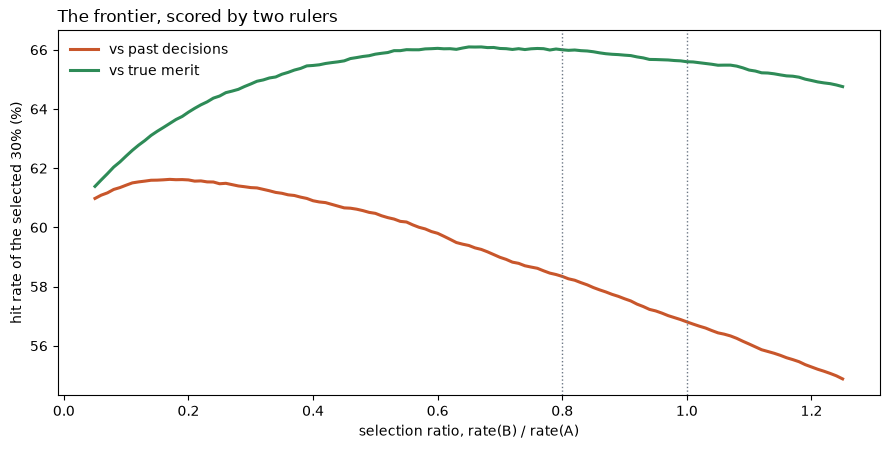

In [7]:
fr = r["frontier"]
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(fr["ratio"], [v * 100 for v in fr["hit_hist"]], color="#c8562b", lw=2.2, label="vs past decisions")
ax.plot(fr["ratio"], [v * 100 for v in fr["hit_true"]], color="#2e8b57", lw=2.2, label="vs true merit")
for x in (0.8, 1.0):
    ax.axvline(x, color="#6b7684", ls=":", lw=1)
ax.set_xlabel("selection ratio, rate(B) / rate(A)")
ax.set_ylabel("hit rate of the selected 30% (%)")
ax.set_title("The frontier, scored by two rulers", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- Against past decisions, moving from the unconstrained model to parity costs 4.8 points of hit rate.
- Against true merit the same move gains 1.6 points: the unconstrained model was reproducing the old bar.
- With an honest history the price of parity is 0.39 points, despite a real 0.25 sd skill gap: the curve is flat at
  the top. Everything above that is the ruler, and it grows with the bias.
- Removing the group, dropping a proxy or reweighing each lands on the frontier, short of four-fifths.
- On a 2,000-row validation set the price reads 1.4 to 5.0 points. Report it as a range, against both rulers if you can
  build the second one (a re-labelled audit sample, an outcome observed later).

## 7. Try your own

In [8]:
# A world with a larger real gap and an honest history - is parity still almost free?
# w = parse_world("skill_gap=0.6, label_bias=0")
# x = one_seed(1, 30_000, w, with_audit=False); print(x["start"], x["prices"])

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version takes your own
world: `pip install -r requirements.txt && streamlit run app.py`.

Sibling builds: [`disparate-impact`](../disparate-impact) measures the gap and why fairness definitions conflict;
[`proxy-variable-finder`](../proxy-variable-finder) finds where the gap enters when the attribute is removed. This one
draws the curve both of them had points on.